# 7 - Relations and probabilistic temporal scene graphs

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").is_file():
    if ROOT.parent == ROOT:
        raise RuntimeError("run this notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)
print("python:  ", sys.version.split()[0], "->", sys.executable)

repo root: /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback
python:   3.14.4 -> /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/venv/bin/python3.14


In [ ]:
import collections
import json as _json
import random
import time
from dataclasses import fields

import numpy as np

from perception.contracts import GraphHistory, RelationPredicate as P
from perception.inference import prerecorded_frames, run_inference
from perception.ontology import load_ontology
from perception.scene_graph import SceneGraphBuilder, SceneGraphConfig, to_asp
from perception.scene_graph import relations as relations_module
from perception.scene_graph.render import (
    draw_graph,
    plot_relation_timeline,
    render_snapshot,
)
from perception.tracking import Tracker, TrackerConfig, collectable_classes
from tests.scenes import run_scene, scene_names

import html

import matplotlib.pyplot as plt
from IPython.display import HTML, display

In [ ]:
def table(rows, columns=None):
    if not rows:
        print("(no rows)")
        return
    columns = columns or list(rows[0])
    head = "".join(
        f"<th style='text-align:left'>{html.escape(str(c))}</th>" for c in columns
    )
    body = "".join(
        "<tr>"
        + "".join(
            f"<td style='text-align:left'>{html.escape(str(r.get(c, '')))}</td>"
            for c in columns
        )
        + "</tr>"
        for r in rows
    )
    display(HTML(f"<table><tr>{head}</tr>{body}</table>"))

In [ ]:
def show_images(images, titles=(), columns=4, size=4.0):

    rows = (len(images) + columns - 1) // columns
    figure, axes = plt.subplots(
        rows, columns, figsize=(size * columns, size * rows), squeeze=False
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, image, title in zip(axes.flat, images, list(titles) + [""] * len(images)):
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
    figure.tight_layout()
    plt.show()

In [ ]:
ONTOLOGY = load_ontology("configs/ontology.json")
TRACKER_CONFIG = TrackerConfig.from_json_file("configs/tracker.json")
GRAPH_CONFIG = SceneGraphConfig.from_json_file("configs/scene_graph.json")
WEIGHTS = Path("runs/detector/notebook_yolo26n_seg/weights/best.pt")
CAPTURES = Path("captures/curriculum_run/rgb")
EXPORT = Path("runs/scene_graph") / time.strftime("%Y%m%d-%H%M%S")  # new folder per run

N_EPISODES = 4   # random curriculum episodes to run
SEED = 7         # change to sample different episodes
STRIDE = 100     # show every STRIDE-th frame
DEVICE = "auto"  # detector device: auto / mps / cpu / cuda:0
print("weights:", WEIGHTS, "found" if WEIGHTS.is_file() else "MISSING")

weights: runs/detector/notebook_yolo26n_seg/weights/best.pt found


## Relation definitions and configuration

In [3]:
print(relations_module.__doc__)
table([{"setting": f.name, "value": getattr(GRAPH_CONFIG, f.name)} for f in fields(GRAPH_CONFIG)])

Hybrid relation engine: deterministic geometry, configurable heuristics, pluggable learned models.

Frames of reference. Image relations (`left_of`, `right_of`, `above`, `below`, `overlaps`, `on`,
`occludes`) are egocentric, in the agent's current view, between *visible* nodes only. Metric
relations (`near`, `far`, `adjacent`, `moving_toward`, `moving_away`) use a floor-contact distance:
Animal-AI's camera has zero pitch at `camera_height`, so a box whose bottom edge sits `v - cy` rows
below the horizon rests `z = camera_height * f / (v - cy)` ahead, `x = (u - cx) * z / f` to the side.
Checked on the curriculum captures: median error <= 10% from 5 to 20 units, so every distance
carries +-`depth_relative_error`. It is unknown (and the relation omitted) when the box bottom is
cut by the frame or within `depth_min_rows_below_horizon` of the horizon, and it is wrong for
objects not resting on the floor.

Every relation is emitted only when it holds with probability >= `min_relation_probabi

setting,value
camera_focal_fraction,0.41955
camera_cx_fraction,0.5
camera_cy_fraction,0.5
camera_height,0.49
depth_relative_error,0.15
depth_min_rows_below_horizon,2.0
lateral_margin_fraction,0.02
above_min_horizontal_overlap,0.3
overlap_min_iou,0.05
near_distance,3.0


## Synthetic task fixtures

`tests/fixtures/scenes/*.json` are small keyframed scenes (256x256, horizon at row 128) run through
the real tracker and builder — the same graphs `tests/unit/test_scene_graph.py` asserts on. For each
fixture: the first frame, the frame the fixture is about, and the last frame.

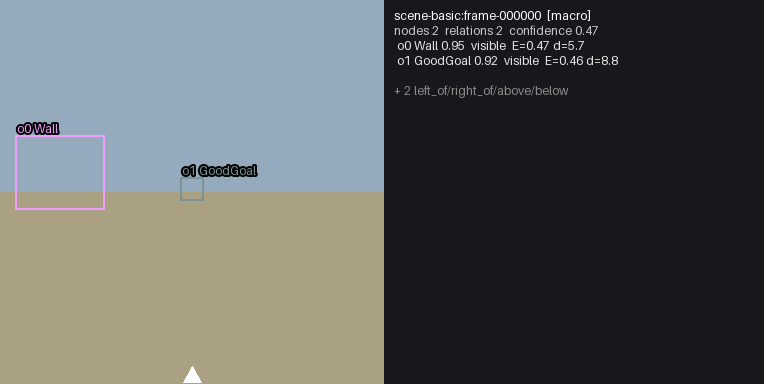

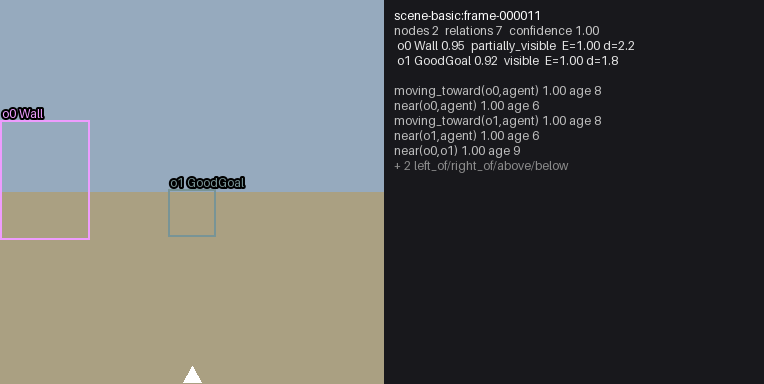

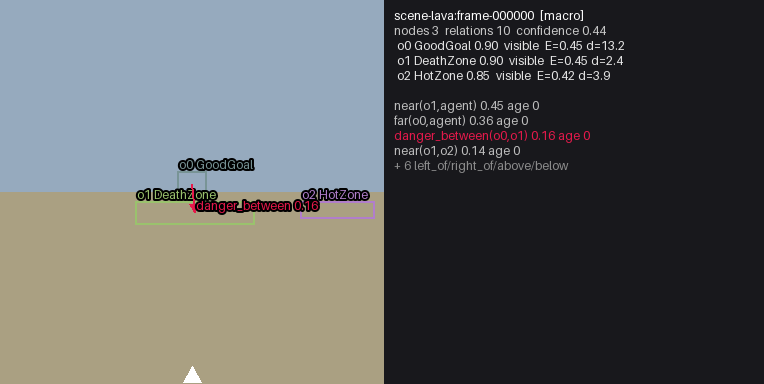

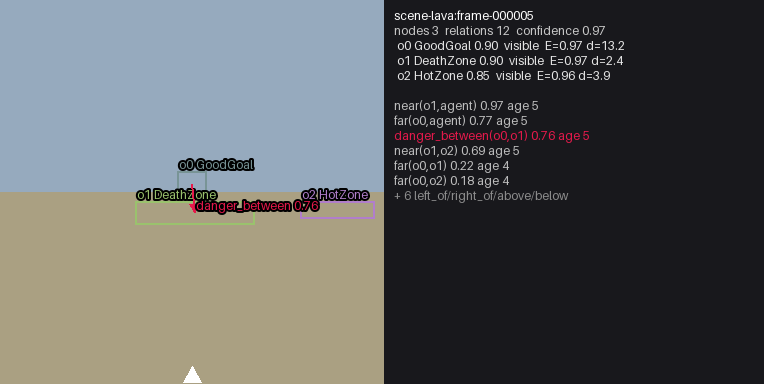

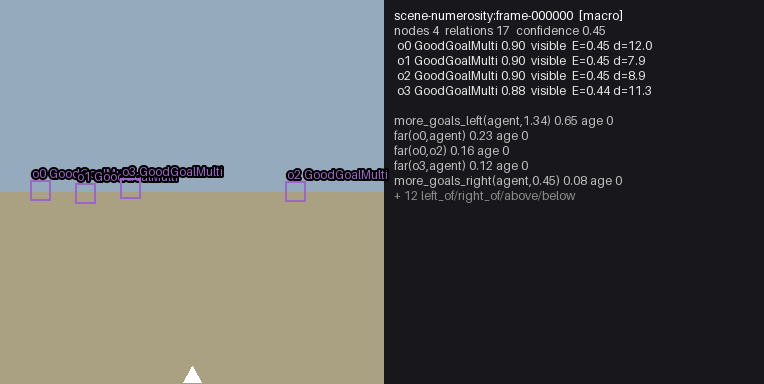

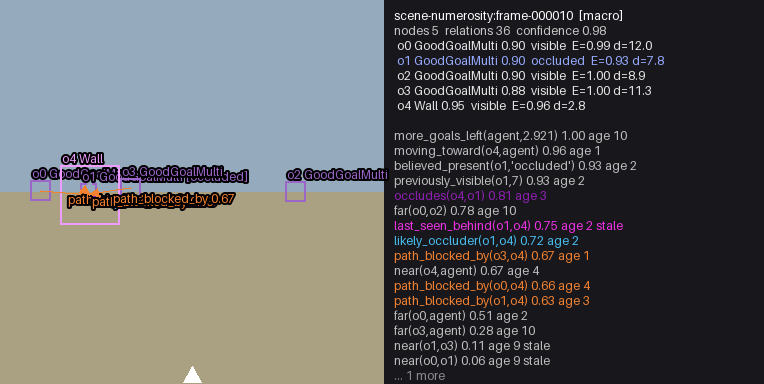

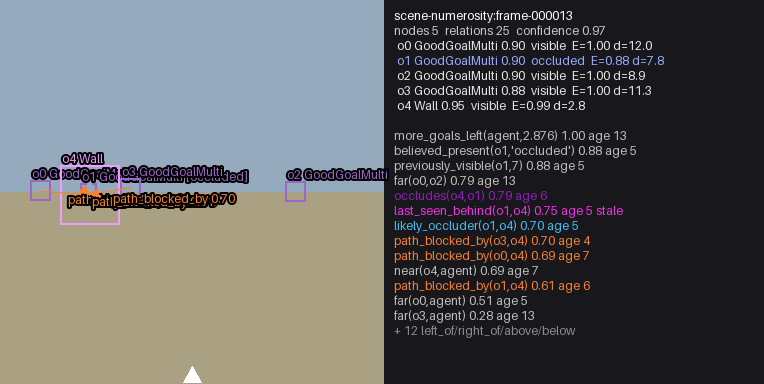

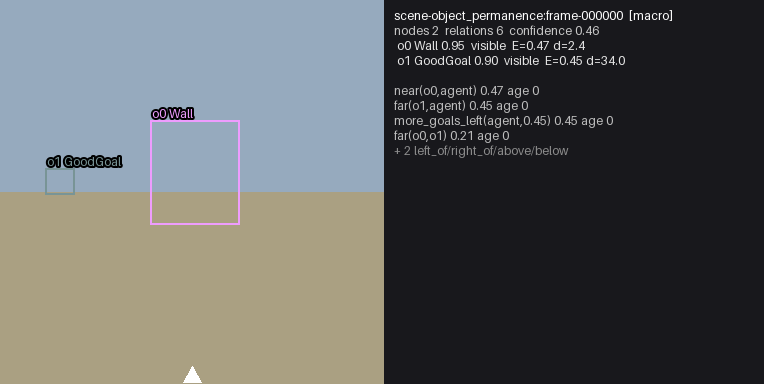

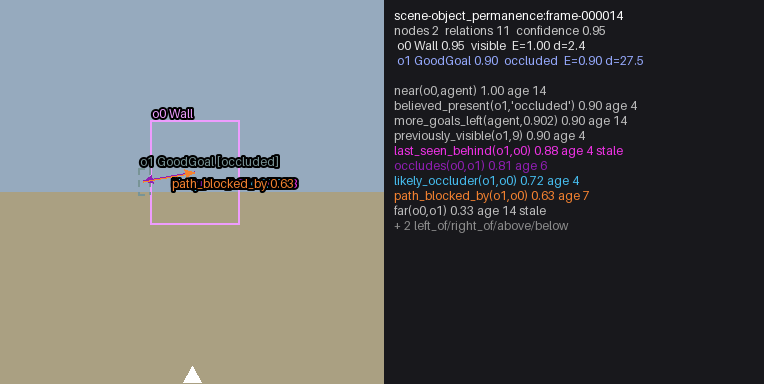

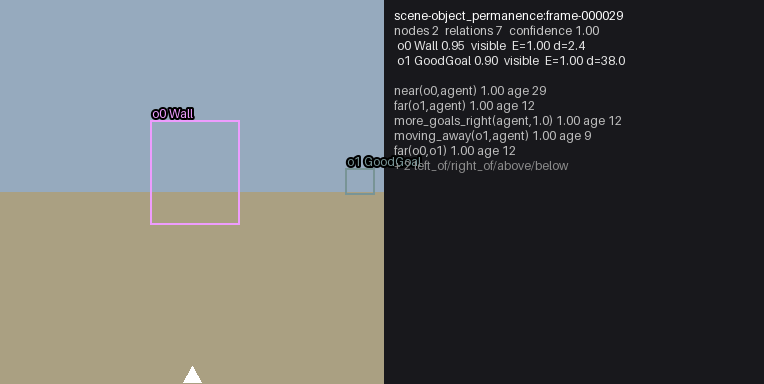

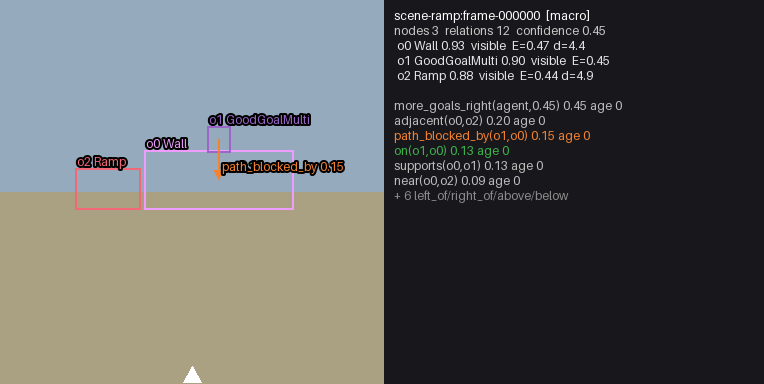

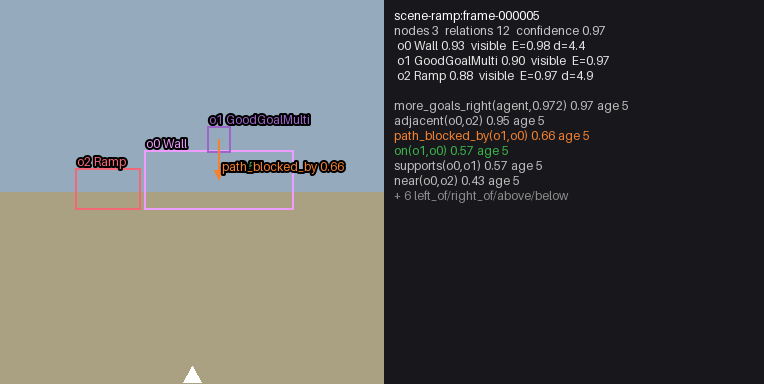

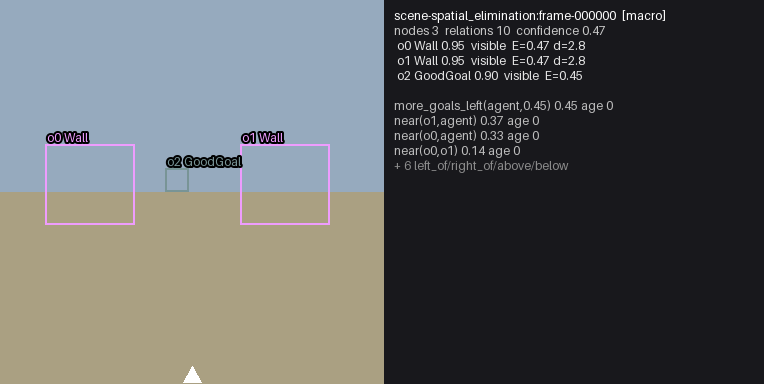

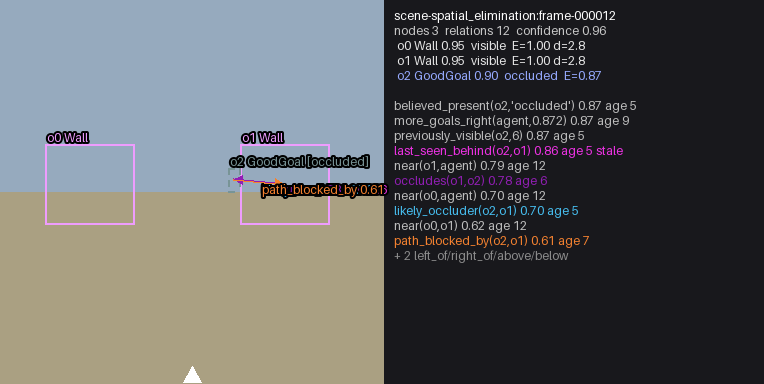

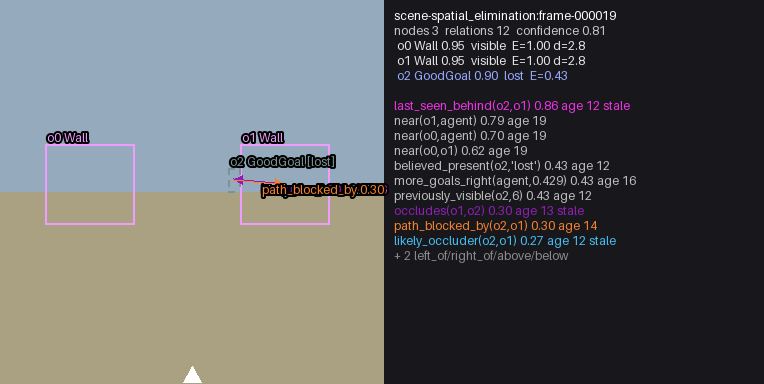

In [4]:
FOCUS = {  # frame each fixture is about
    "basic": -1, "lava": -1, "ramp": -1, "numerosity": 10,
    "spatial_elimination": 12, "object_permanence": 14,
}
fixtures = {name: run_scene(name) for name in scene_names()}
for name, (scene, tracks, snapshots, builder) in fixtures.items():
    display(HTML(f"<h3>{name}</h3><p>{scene['description']}</p>"))
    for index in sorted({0, FOCUS[name] % len(snapshots), len(snapshots) - 1}):
        display(render_snapshot(snapshots[index], size=384, panel_width=380, panel_lines=24))

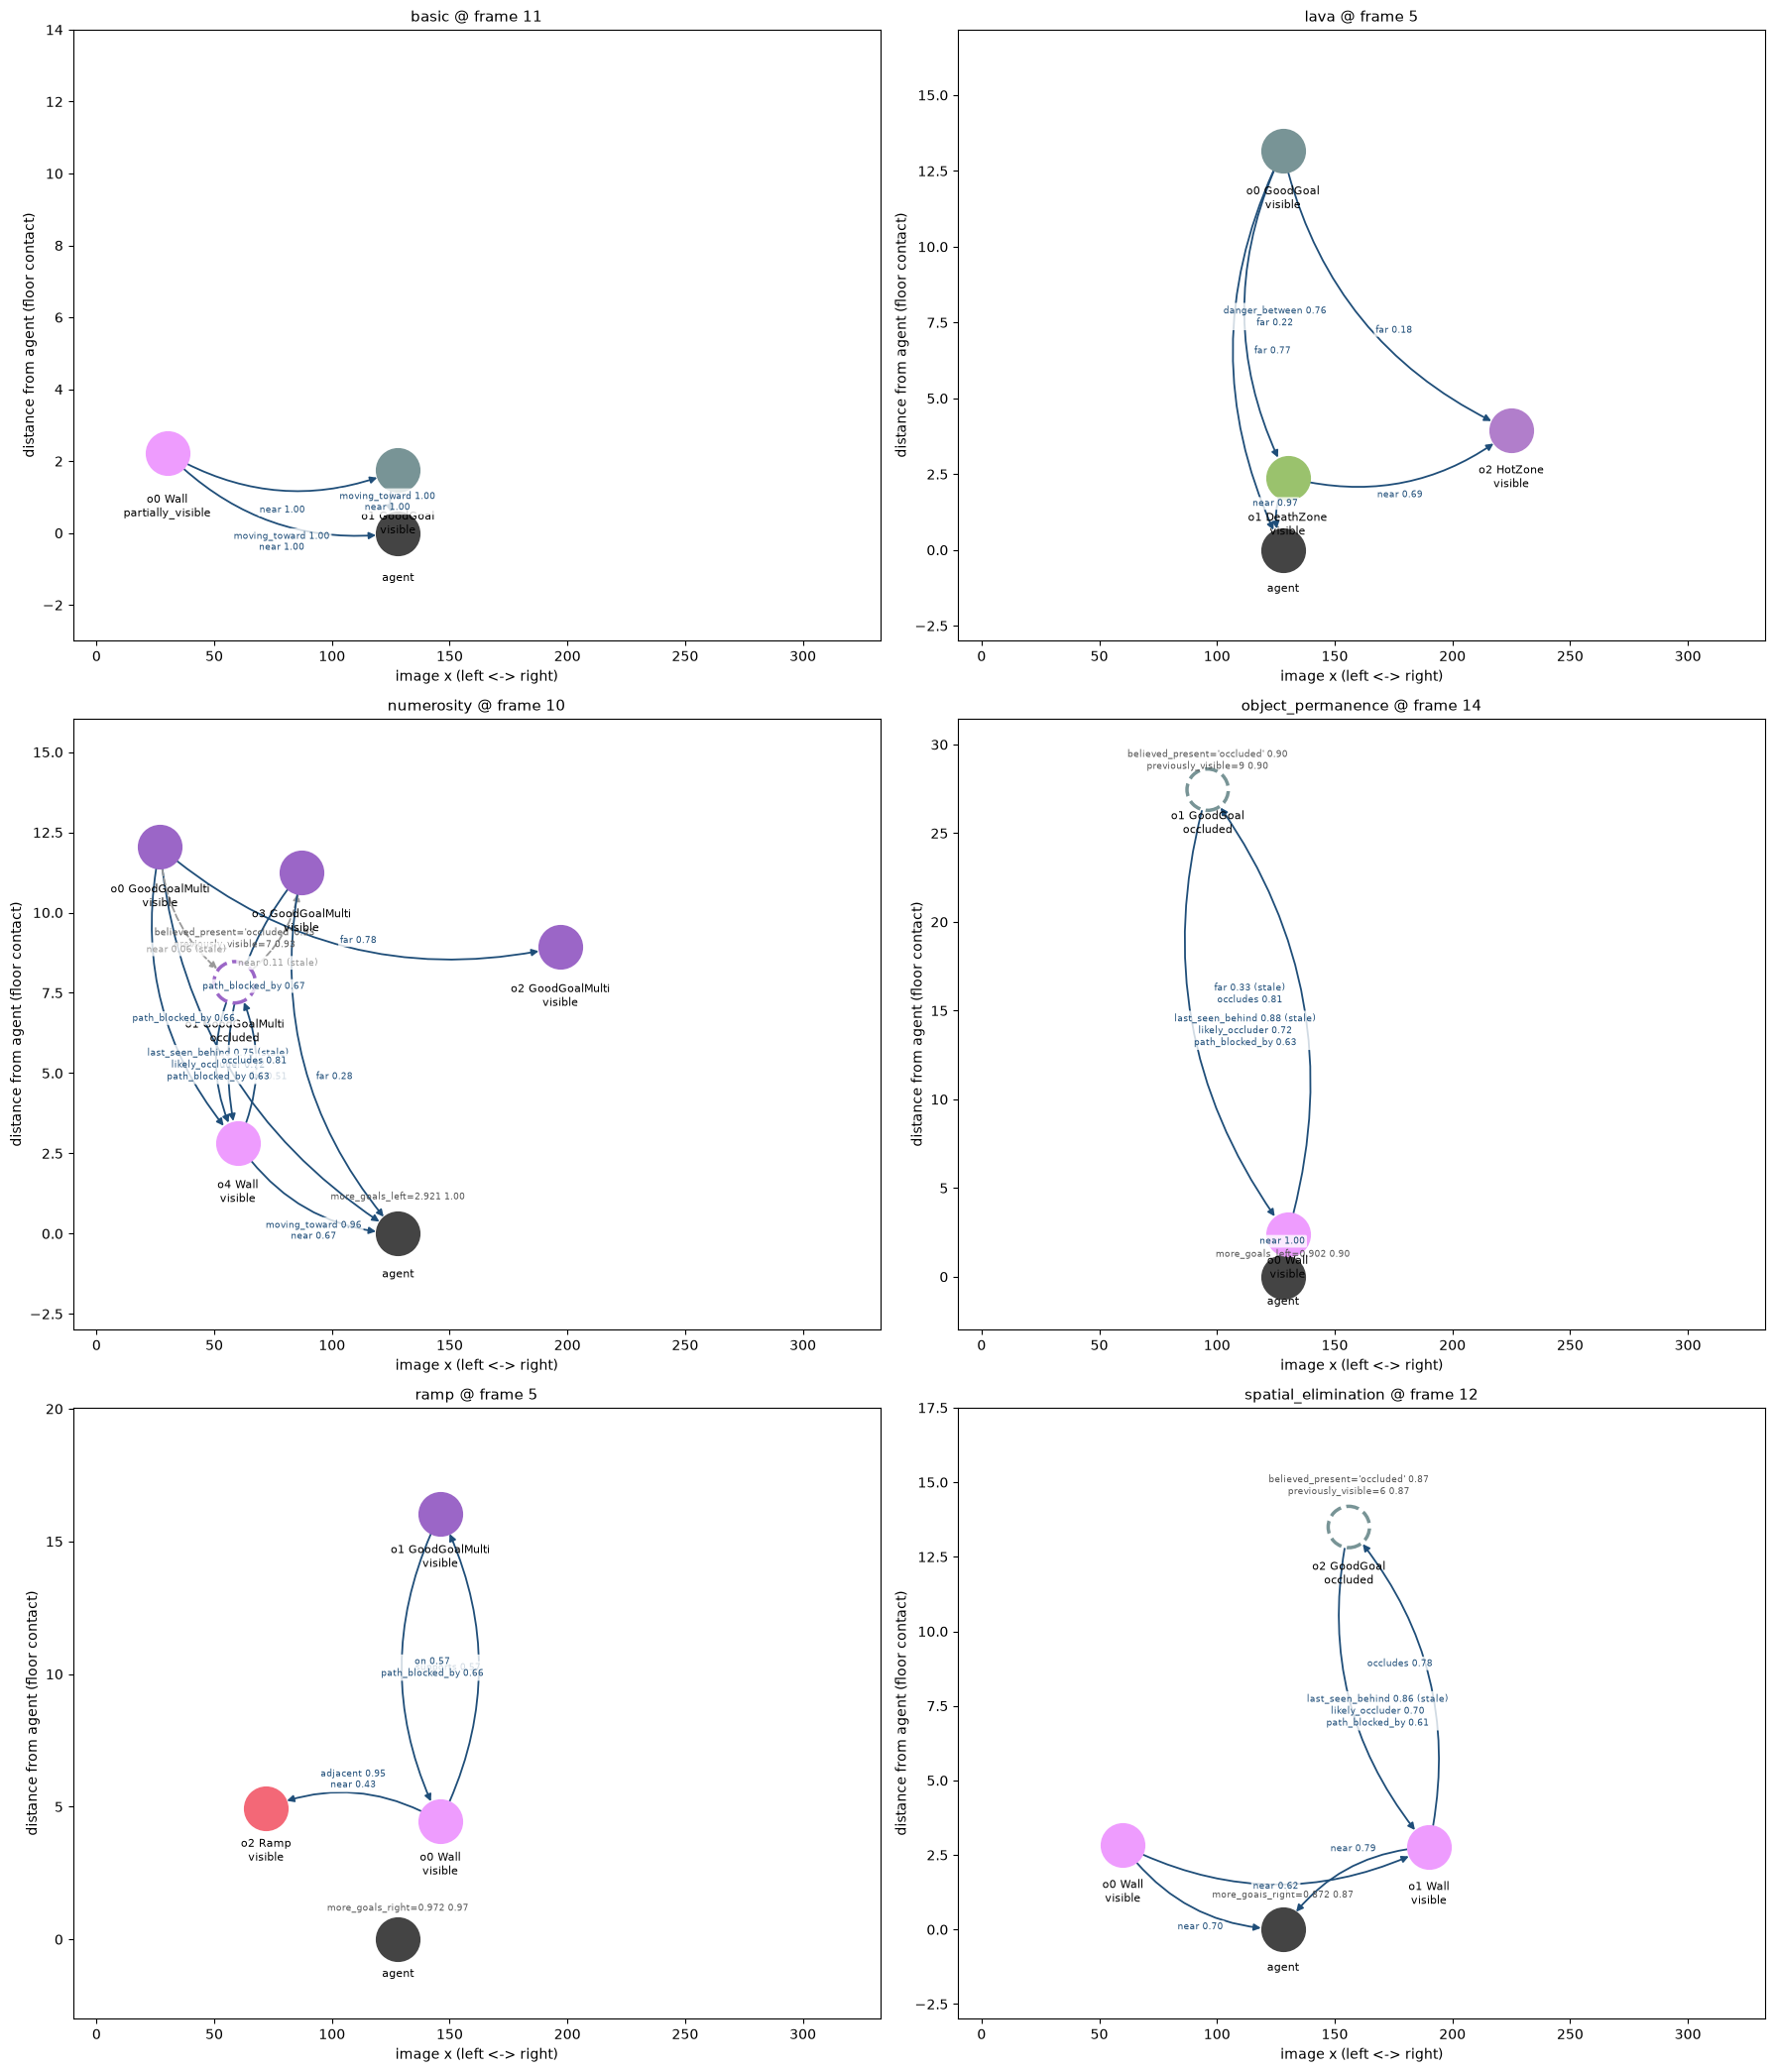

In [5]:
figure, axes = plt.subplots(3, 2, figsize=(18, 21))
for ax, (name, (scene, tracks, snapshots, builder)) in zip(axes.flat, fixtures.items()):
    draw_graph(snapshots[FOCUS[name]], ax=ax)
    ax.set_title(f"{name} @ frame {snapshots[FOCUS[name]].stamp.frame_index}", fontsize=11)
figure.tight_layout()
plt.show()

In [6]:
TASK_EDGES = (P.DANGER_BETWEEN, P.ON, P.SUPPORTS, P.ADJACENT, P.MORE_GOALS_LEFT, P.MORE_GOALS_RIGHT, P.PATH_BLOCKED_BY,
              P.LAST_SEEN_BEHIND, P.LIKELY_OCCLUDER, P.BELIEVED_PRESENT, P.REAPPEARED_AFTER, P.MOVING_TOWARD)
rows = []
for name, (scene, tracks, snapshots, builder) in fixtures.items():
    snapshot = snapshots[FOCUS[name]]
    for r in snapshot.relations:
        if r.predicate in TASK_EDGES:
            rows.append({"fixture": name, "frame": snapshot.stamp.frame_index, "relation": r.predicate.value,
                         "subject": r.subject_node_id.rsplit("_", 1)[-1],
                         "object / value": r.object_node_id.rsplit("_", 1)[-1] if r.object_node_id else repr(r.symbolic_value),
                         "p": f"{r.probability:.2f}", "age": r.age_frames, "source": r.source.source.value,
                         "evidence": ", ".join(r.evidence)})
table(rows)

fixture,frame,relation,subject,object / value,p,age,source,evidence
basic,11,moving_toward,0000,agent,1.00,8,geometry,range_rate=-2.35/s
basic,11,moving_toward,0001,agent,1.00,8,geometry,range_rate=-2.72/s
lava,5,danger_between,0000,0001,0.76,5,task_rule,on_straight_path
numerosity,10,believed_present,0001,'occluded',0.93,2,temporal_memory,
numerosity,10,last_seen_behind,0001,0004,0.75,2,temporal_memory,"tracker_occluder, stale_frames=2"
numerosity,10,likely_occluder,0001,0004,0.72,2,tracker,tracker_occluder
numerosity,10,more_goals_left,agent,2.921,1.00,10,task_rule,"expected_left=2.92, expected_right=1.00, includes_memory_only"
numerosity,10,moving_toward,0004,agent,0.96,1,geometry,range_rate=-1.99/s
numerosity,10,path_blocked_by,0000,0004,0.66,4,task_rule,on_straight_path
numerosity,10,path_blocked_by,0001,0004,0.63,3,task_rule,on_straight_path


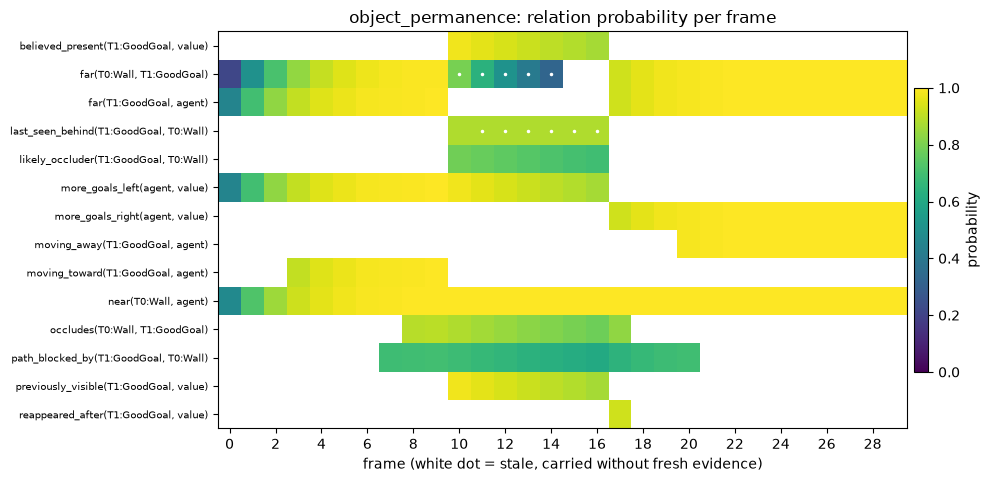

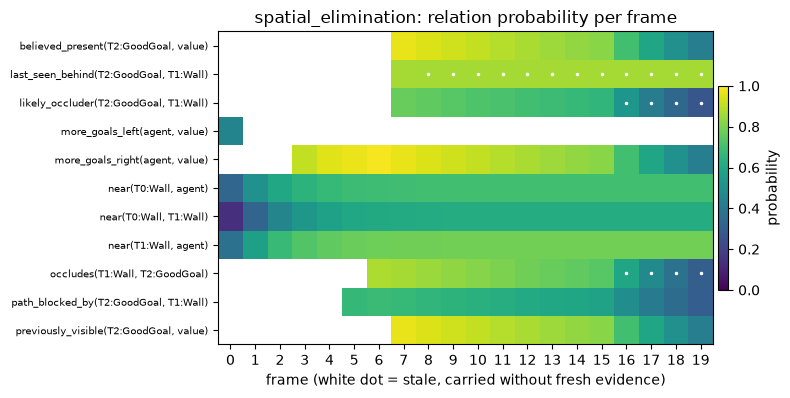

In [7]:
for name in ("object_permanence", "spatial_elimination"):
    plot_relation_timeline(fixtures[name][2], title=f"{name}: relation probability per frame")
    plt.show()

## Captured curriculum episodes

Episodes are sampled at random (seeded) among `captures/curriculum_run/rgb/*` with at least
`STRIDE + 1` frames, so each shows two or more snapshots. The detector trained on some of these
episodes' frames — this section shows graph construction, not detector generalisation (held-out
episodes are marked `test split`).

In [8]:
test_split = {_json.loads(line)["episode_id"] for line in open("datasets/animalai_merged/metadata/test.jsonl")} \
    if Path("datasets/animalai_merged/metadata/test.jsonl").is_file() else set()
lengths = {p.name: sum(1 for _ in p.glob("*.png")) for p in sorted(CAPTURES.iterdir()) if p.is_dir()}
candidates = sorted(name for name, n in lengths.items() if n > STRIDE)
episodes = sorted(random.Random(SEED).sample(candidates, min(N_EPISODES, len(candidates))))
table([{"episode": name, "frames": lengths[name], "split": "test" if name in test_split else ""} for name in episodes])

episode,frames,split
curriculum-0031,105,
curriculum-0077,197,
curriculum-0085,159,
curriculum-0107,173,


In [9]:
from perception.inference.yolo import YoloDetector

detector = YoloDetector(WEIGHTS, device=DEVICE)
runs = {}
for name in episodes:
    tracker = Tracker(TRACKER_CONFIG, collectable_classes(ONTOLOGY))
    builder = SceneGraphBuilder(GRAPH_CONFIG, ONTOLOGY)
    shown, graphs = {}, []
    last_index = lengths[name] - 1

    def keep(frame, graph, shown=shown, graphs=graphs, last_index=last_index):
        graphs.append(graph)
        if graph.stamp.frame_index % STRIDE == 0 or graph.stamp.frame_index == last_index:
            shown[graph.stamp.frame_index] = (frame.image, graph)

    summary = run_inference(detector, prerecorded_frames(CAPTURES / name), ontology=ONTOLOGY,
                            tracker=tracker, graph_builder=builder, on_graph=keep)
    runs[name] = {"shown": shown, "graphs": graphs, "builder": builder, "summary": summary}
table([{"episode": n, "frames": r["summary"]["frames"], "relations": r["summary"]["scene_graph"]["relations"],
        "macro steps": r["summary"]["scene_graph"]["macro_steps"],
        "graph ms/frame": f"{r['summary']['latency_ms']['graph']['p50']:.2f}",
        "detector fps": f"{r['summary']['throughput']['detector_fps']:.0f}"} for n, r in runs.items()])

episode,frames,relations,macro steps,graph ms/frame,detector fps
curriculum-0031,105,16552,11,1.78,51
curriculum-0077,197,1069,20,0.19,68
curriculum-0085,159,1380,16,0.25,65
curriculum-0107,173,4077,18,0.63,61


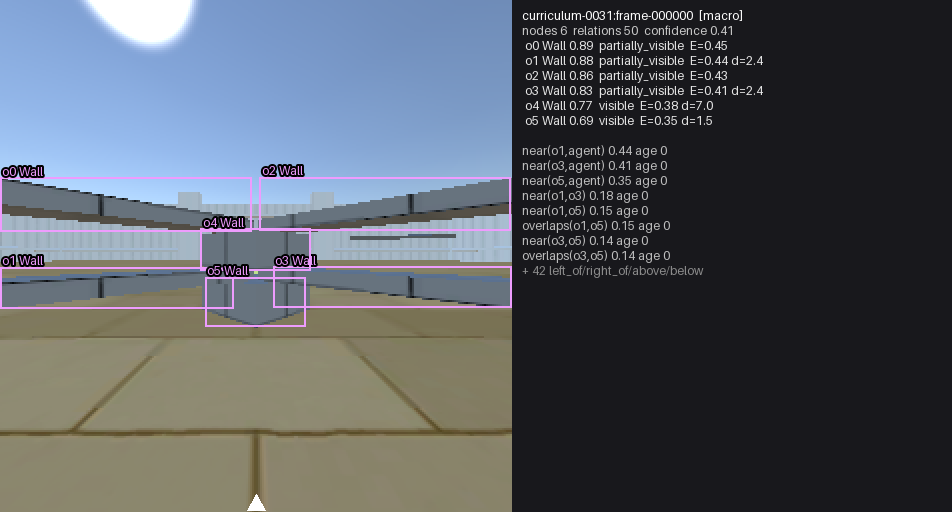

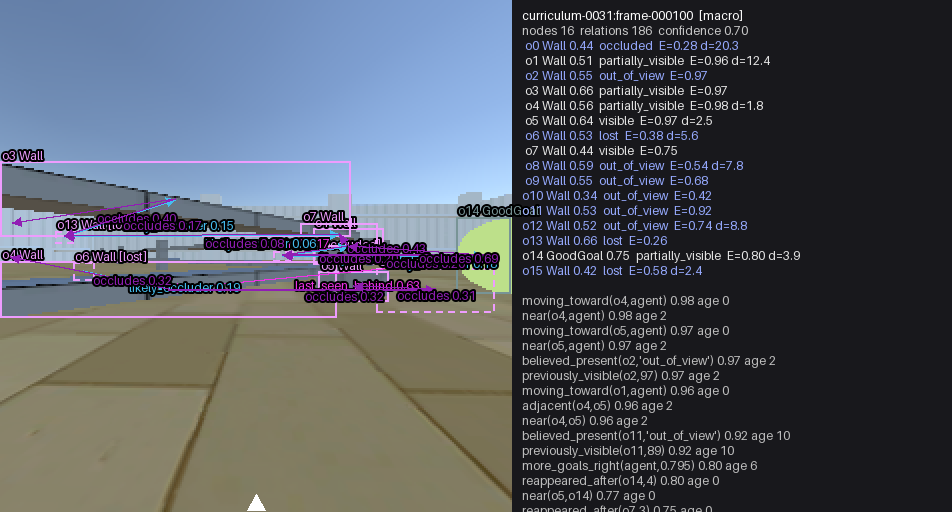

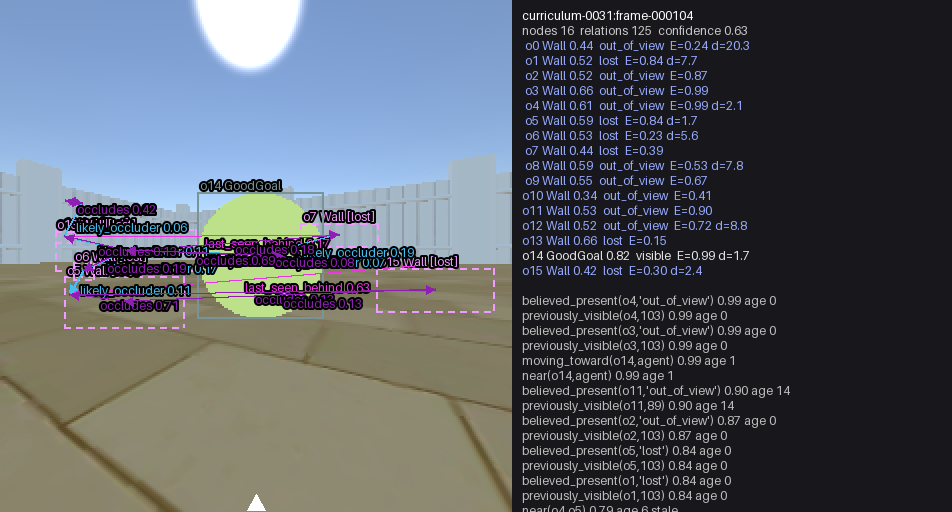

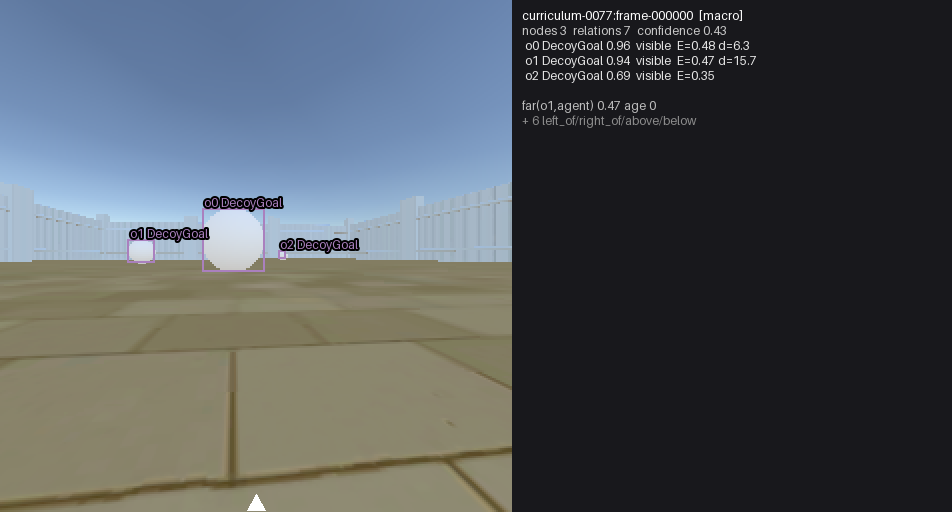

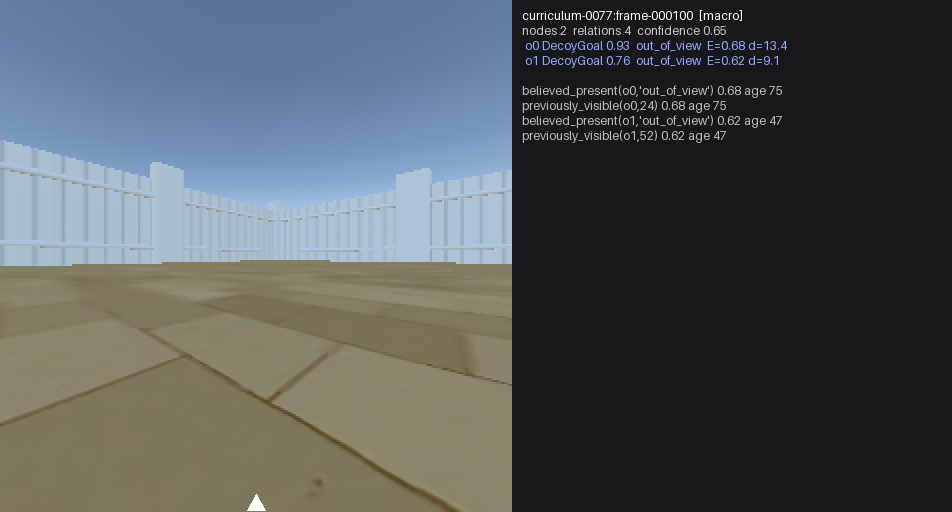

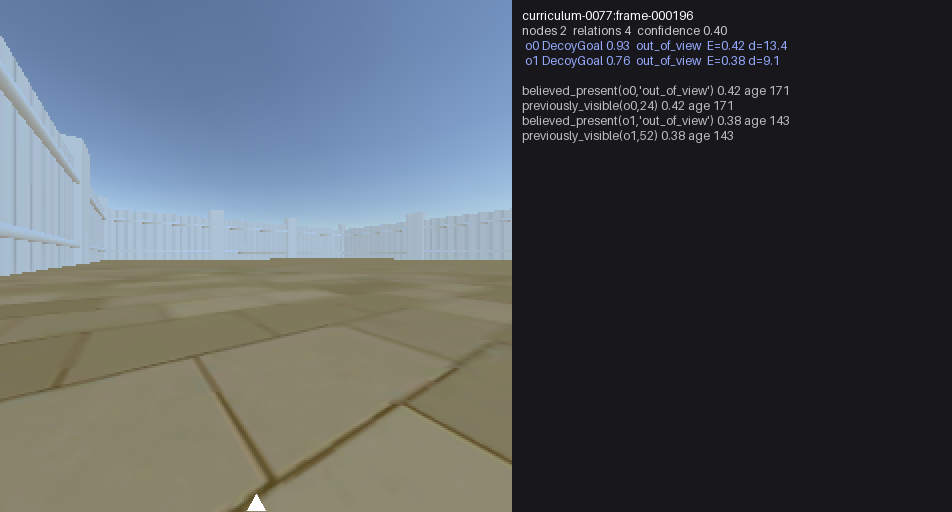

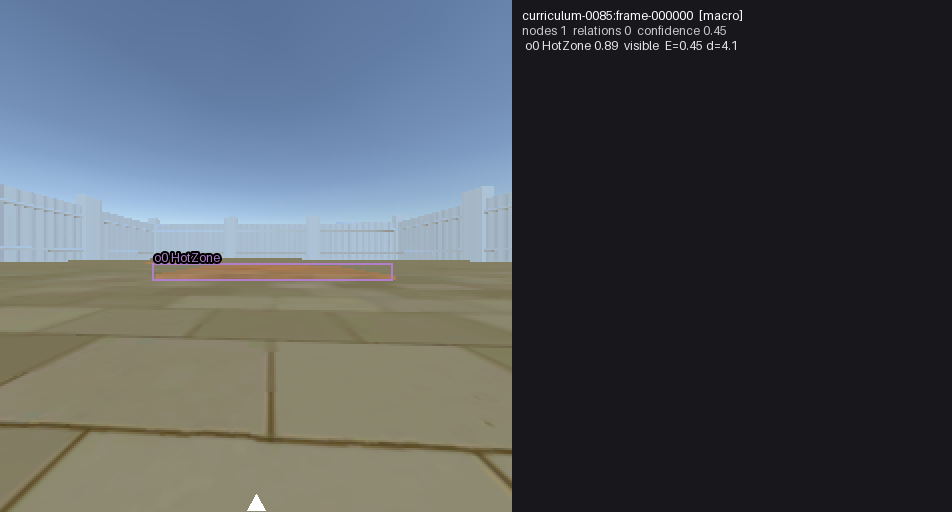

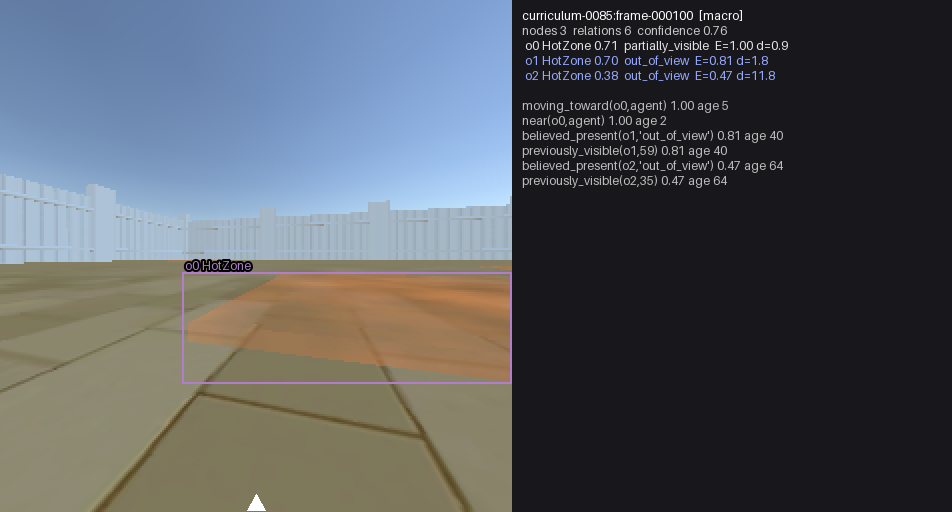

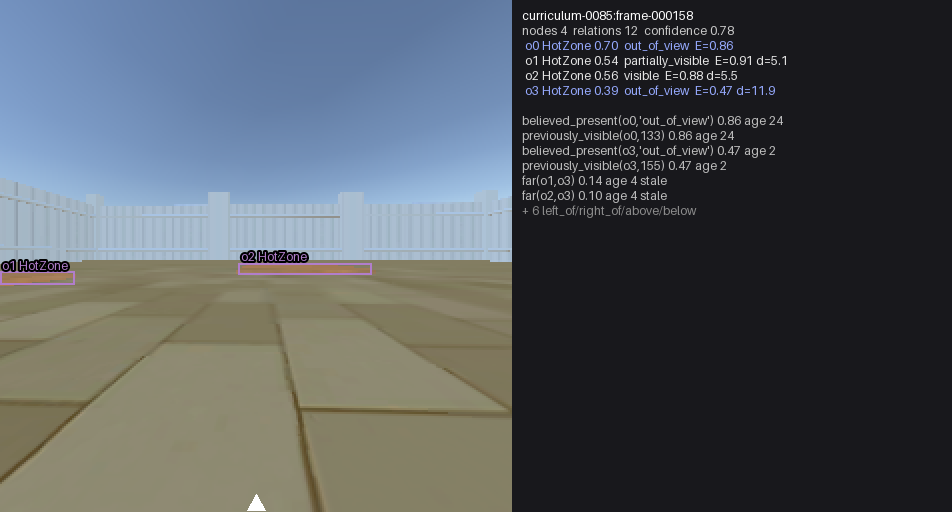

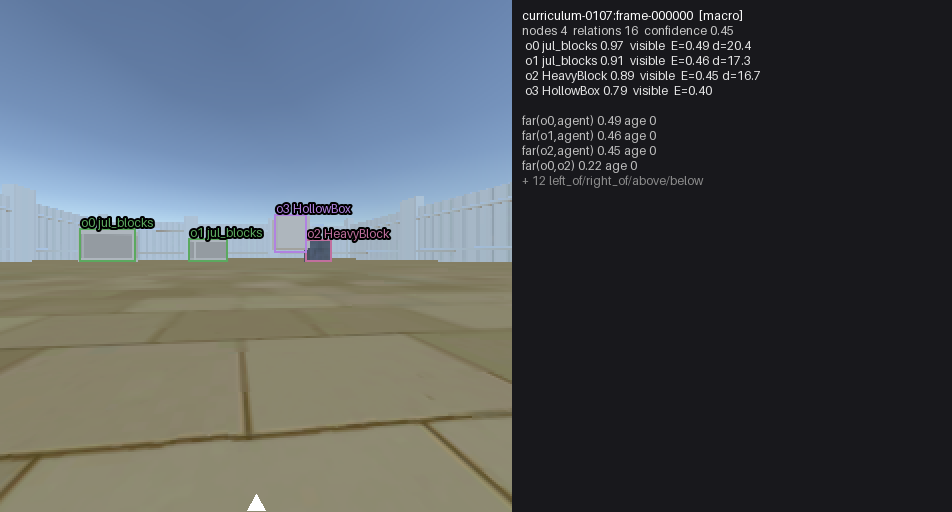

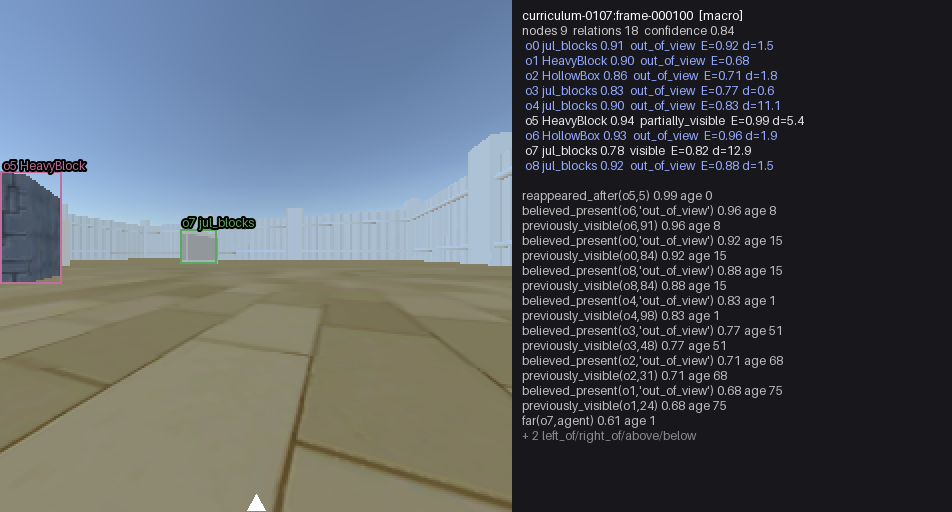

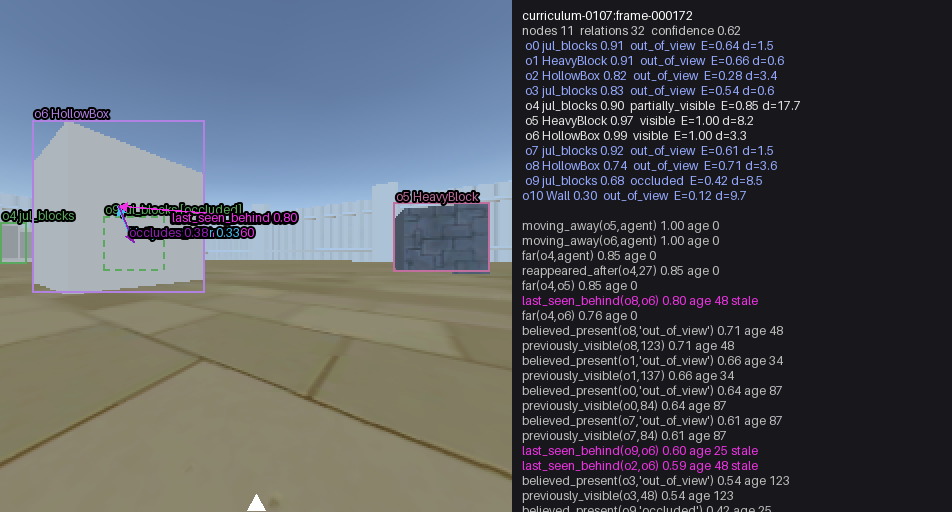

In [10]:
for name, run in runs.items():
    display(HTML(f"<h3>{name}</h3>"))
    for index, (image, graph) in sorted(run["shown"].items()):
        display(render_snapshot(graph, image, size=512, panel_width=440, panel_lines=40))

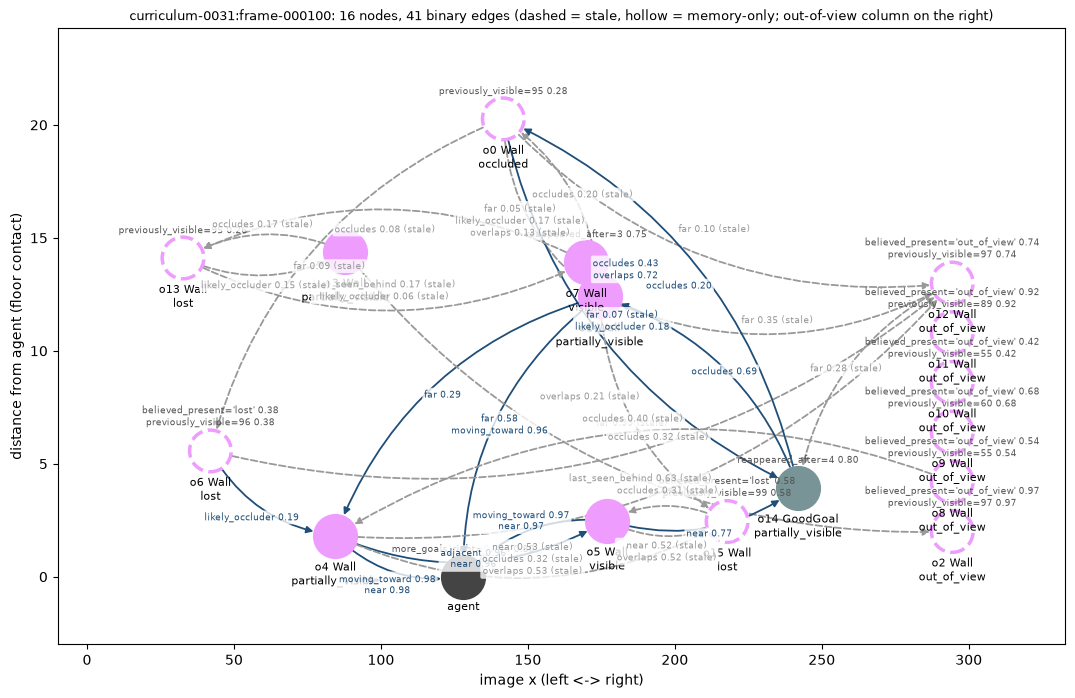

In [11]:
name, (image, snapshot) = max(((n, item) for n, r in runs.items() for item in r["shown"].values()),
                             key=lambda pair: len(pair[1][1].relations))
draw_graph(snapshot)
plt.show()

In [12]:
labels = {n.node_id: f"{n.semantic_distribution.entries[0].label if n.semantic_distribution.entries else '?'} ({n.memory_state.value})"
          for n in snapshot.objects}
table([{"relation": r.predicate.value, "subject": labels.get(r.subject_node_id, r.subject_node_id),
        "object / value": labels.get(r.object_node_id, r.object_node_id) if r.object_node_id else repr(r.symbolic_value),
        "p": f"{r.probability:.2f}", "age": r.age_frames, "source": r.source.source.value, "evidence": ", ".join(r.evidence)}
       for r in sorted(snapshot.relations, key=lambda r: (r.predicate.value, -r.probability))
       if r.predicate not in (P.LEFT_OF, P.RIGHT_OF, P.ABOVE, P.BELOW)])

relation,subject,object / value,p,age,source,evidence
adjacent,Wall (partially_visible),Wall (visible),0.96,2,geometry,gap_px=-9.4
believed_present,Wall (out_of_view),'out_of_view',0.97,2,temporal_memory,
believed_present,Wall (out_of_view),'out_of_view',0.92,10,temporal_memory,
believed_present,Wall (out_of_view),'out_of_view',0.74,2,temporal_memory,
believed_present,Wall (out_of_view),'out_of_view',0.68,39,temporal_memory,
believed_present,Wall (lost),'lost',0.58,0,temporal_memory,
believed_present,Wall (out_of_view),'out_of_view',0.54,44,temporal_memory,
believed_present,Wall (out_of_view),'out_of_view',0.42,44,temporal_memory,
believed_present,Wall (lost),'lost',0.38,3,temporal_memory,
far,Wall (partially_visible),agent,0.58,3,geometry,


In [13]:
print(to_asp(snapshot, min_probability=0.5))

% curriculum-0031:frame-000100 t=6.000 macro=true
agent(agent).
object(obj_curriculum_0031_track_0000).
memory_only(obj_curriculum_0031_track_0000).
state(obj_curriculum_0031_track_0000,occluded).
existence(obj_curriculum_0031_track_0000,281).
class(obj_curriculum_0031_track_0000,"Wall",443).
object(obj_curriculum_0031_track_0002).
visible(obj_curriculum_0031_track_0002).
state(obj_curriculum_0031_track_0002,partially_visible).
existence(obj_curriculum_0031_track_0002,960).
class(obj_curriculum_0031_track_0002,"Wall",514).
type(obj_curriculum_0031_track_0002,barrier,1000).
type(obj_curriculum_0031_track_0002,occluder,1000).
type(obj_curriculum_0031_track_0002,support,1000).
object(obj_curriculum_0031_track_0003).
memory_only(obj_curriculum_0031_track_0003).
state(obj_curriculum_0031_track_0003,out_of_view).
existence(obj_curriculum_0031_track_0003,972).
class(obj_curriculum_0031_track_0003,"Wall",545).
type(obj_curriculum_0031_track_0003,barrier,1000).
type(obj_curriculum_0031_track_00

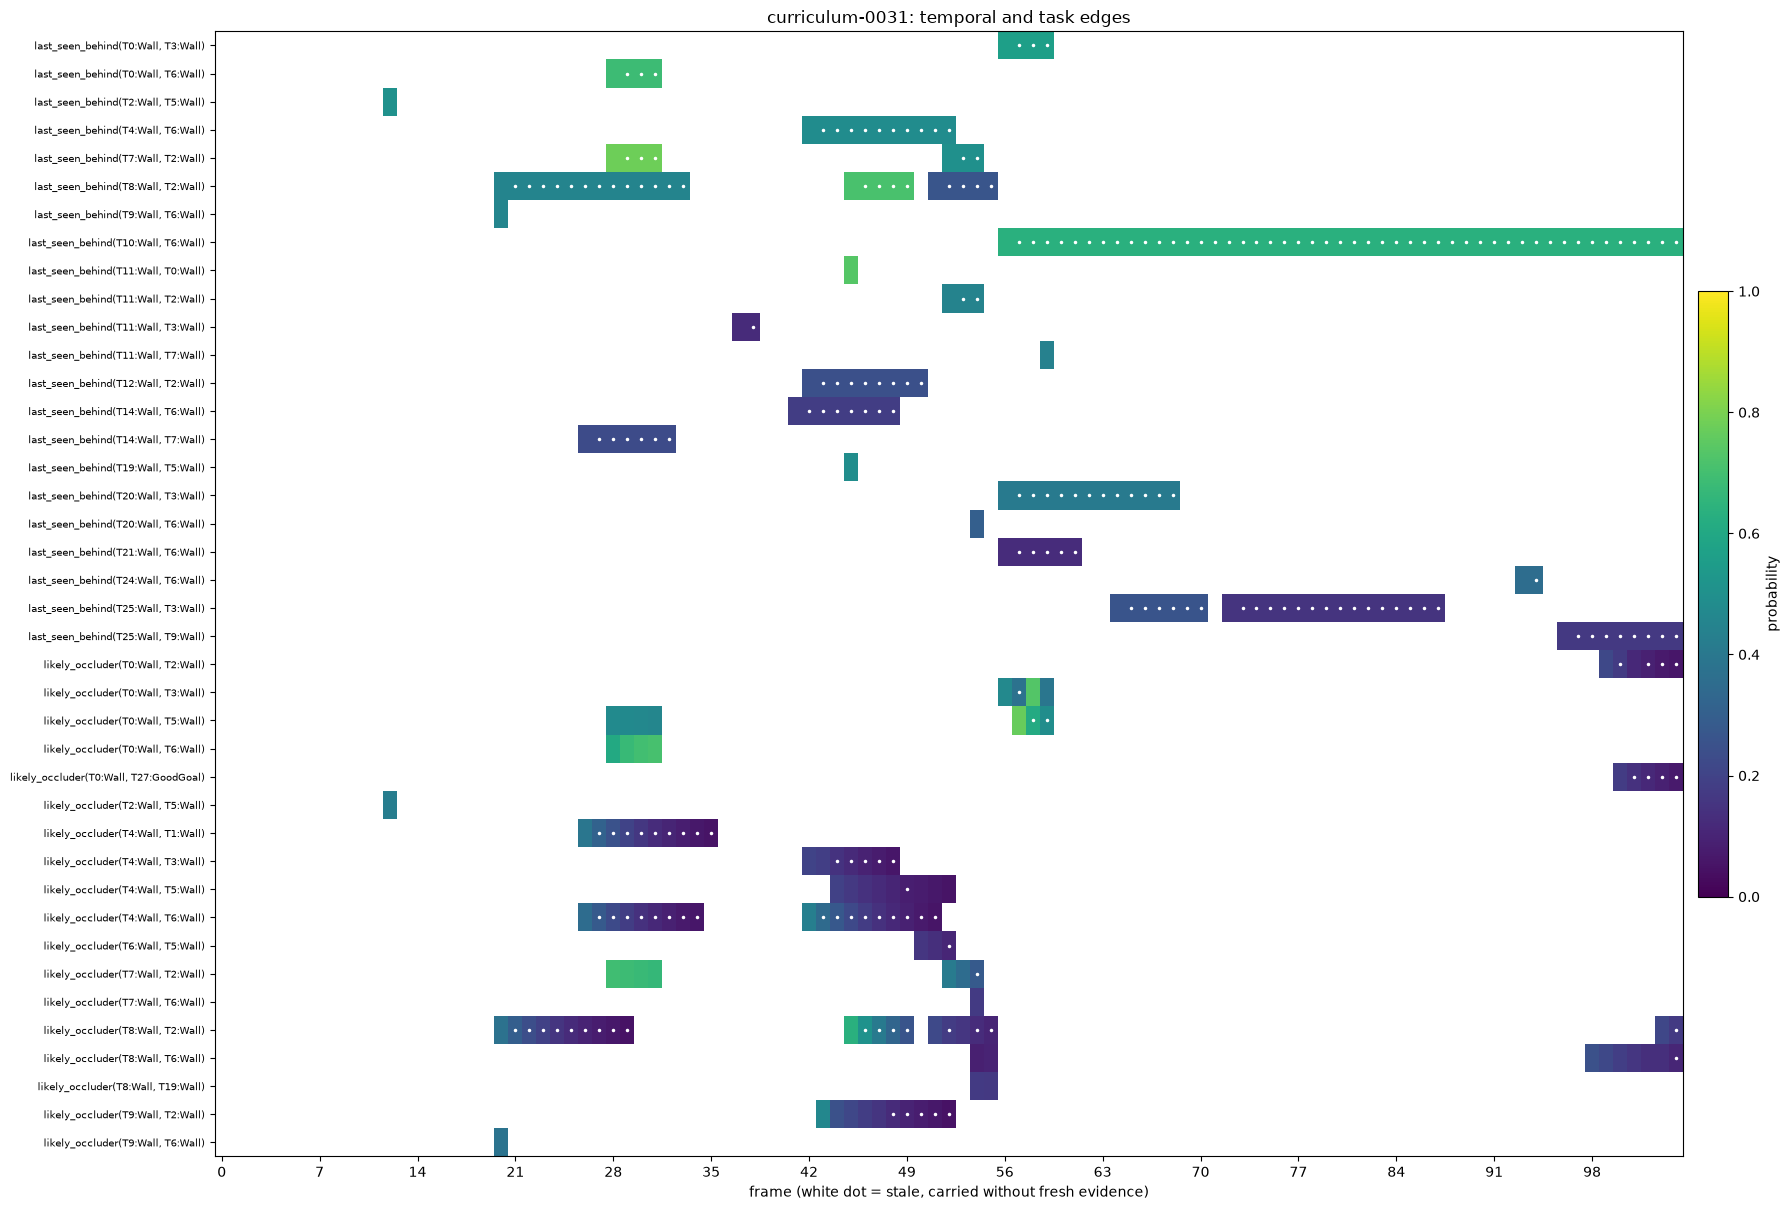

In [14]:
TEMPORAL_AND_TASK = (P.LAST_SEEN_BEHIND, P.LIKELY_OCCLUDER, P.REAPPEARED_AFTER, P.MORE_GOALS_LEFT, P.MORE_GOALS_RIGHT,
                     P.DANGER_BETWEEN, P.PATH_BLOCKED_BY, P.ON, P.OCCLUDES)
busiest = max(runs, key=lambda n: sum(len(g.relations) for g in runs[n]["graphs"]))
plot_relation_timeline(runs[busiest]["graphs"], predicates=TEMPORAL_AND_TASK, max_rows=40,
                       title=f"{busiest}: temporal and task edges")
plt.show()

In [15]:
EXPORT.mkdir(parents=True, exist_ok=False)  # never overwrite anything under runs/
for name, run in runs.items():
    history = run["builder"].history(macro_only=True)
    path = EXPORT / f"{name}_macro_history.json"
    path.write_text(history.to_json(), encoding="utf-8")
    assert GraphHistory.from_json_file(path) == history, name
    print(f"{path}: {len(history.snapshots)} macro snapshots, re-imported identically")

runs/scene_graph/20260926-145830/curriculum-0031_macro_history.json: 11 macro snapshots, re-imported identically
runs/scene_graph/20260926-145830/curriculum-0077_macro_history.json: 20 macro snapshots, re-imported identically
runs/scene_graph/20260926-145830/curriculum-0085_macro_history.json: 16 macro snapshots, re-imported identically


runs/scene_graph/20260926-145830/curriculum-0107_macro_history.json: 18 macro snapshots, re-imported identically


episode,snapshots,distinct nodes,visible node-frames,memory-only node-frames,edges / frame,reappearances,last_seen_behind created
curriculum-0031,105,29,605,893,157.6,128,26
curriculum-0077,197,3,65,404,5.4,9,2
curriculum-0085,159,5,133,329,8.7,31,6
curriculum-0107,173,14,270,1188,23.6,27,6


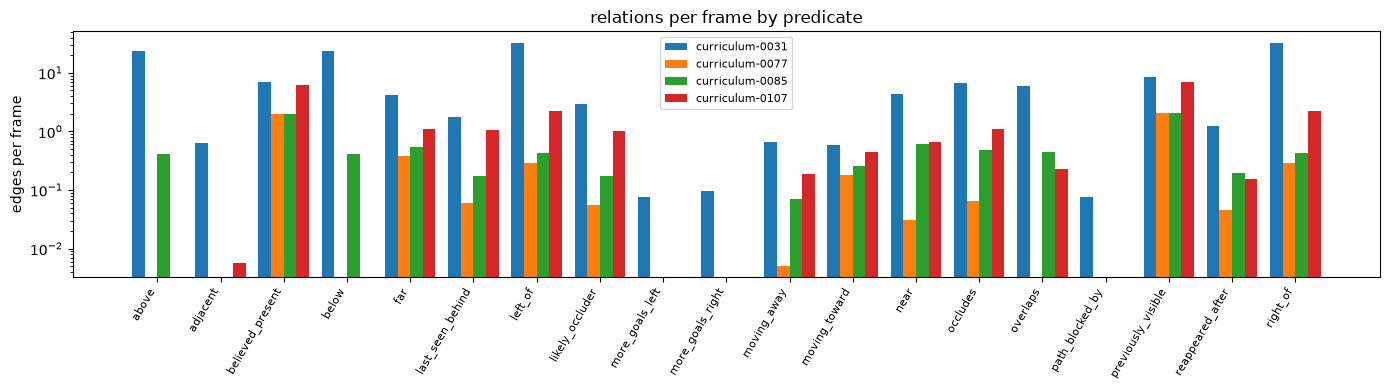

In [16]:
rows = []
for name, run in runs.items():
    g = run["graphs"]
    states = collections.Counter(n.memory_state.value for s in g for n in s.objects)
    created = collections.Counter(r.predicate.value for s in g for r in s.relations if r.age_frames == 0)
    rows.append({"episode": name, "snapshots": len(g), "distinct nodes": len({n.node_id for s in g for n in s.objects}),
                 "visible node-frames": states["visible"] + states["partially_visible"],
                 "memory-only node-frames": sum(v for k, v in states.items() if k not in ("visible", "partially_visible")),
                 "edges / frame": round(sum(len(s.relations) for s in g) / len(g), 1),
                 "reappearances": created["reappeared_after"], "last_seen_behind created": created["last_seen_behind"]})
table(rows)
predicates = sorted({r.predicate.value for run in runs.values() for s in run["graphs"] for r in s.relations})
figure, ax = plt.subplots(figsize=(14, 4))
width = 0.8 / len(runs)
for k, (name, run) in enumerate(runs.items()):
    counts = collections.Counter(r.predicate.value for s in run["graphs"] for r in s.relations)
    ax.bar(np.arange(len(predicates)) + k * width, [counts[p] / len(run["graphs"]) for p in predicates], width, label=name)
ax.set_xticks(np.arange(len(predicates)) + 0.4 - width / 2, predicates, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("edges per frame"); ax.set_yscale("log"); ax.legend(fontsize=8); ax.set_title("relations per frame by predicate")
figure.tight_layout()
plt.show()